# 📊 App User Behavior Segmentation Using Unsupervised Machine Learning

**Domain:** User Behavior Analytics · Machine Learning
**Goal:** Group 50,000 app users by behaviour and engagement (no labels), identify high-engagement and at-risk users, and map every segment to a business action.

**Pipeline:** Data Understanding → Cleaning → EDA → Feature Engineering & Selection → Scaling (StandardScaler) → K-Means (Elbow + Silhouette) → PCA Visualisation → Cluster Profiling → User-level Lists → Business Action Mapping

In [1]:
import time, warnings, joblib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, MiniBatchKMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})

ROOT = Path("..")
DATA = ROOT / "data" / "app_user_behavior_dataset.csv"
FIG, MODELS, OUT = ROOT / "figures", ROOT / "models", ROOT / "outputs"
for p in (FIG, MODELS, OUT):
    p.mkdir(exist_ok=True)

RANDOM_STATE = 42
def savefig(name):
    plt.tight_layout(); plt.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight"); plt.show()

## 1. Data Collection & Understanding

In [2]:
df = pd.read_csv(DATA)
print("Shape:", df.shape)
df.head()

Shape: (50000, 25)


,user_id,age,gender,country,device_type,app_version,sessions_per_week,avg_session_duration_min,daily_active_minutes,feature_clicks_per_session,...,days_since_last_login,subscription_type,ads_clicked_last_30_days,content_downloads,social_shares,rating_given,churn_risk_score,engagement_score,account_age_days,marketing_source
0,100000,56,Female,India,iOS,2.1,5,3.41,52.71,13,...,20,Basic,9,5,2,NaN,0.31,55.79,1152,Referral
1,100001,46,Male,UK,iOS,1.0,8,24.44,42.03,7,...,7,Free,8,3,3,3.0,0.87,82.39,1059,Email Campaign
2,100002,32,Female,UK,iOS,1.2,12,5.34,76.69,7,...,33,Free,11,6,1,2.0,0.63,42.49,678,Google Ads
3,100003,25,Male,India,Android,2.0,5,3.98,65.38,16,...,17,Basic,6,3,1,3.0,0.43,62.81,92,Organic
4,100004,38,Male,Australia,Android,1.0,10,12.85,57.06,13,...,21,Basic,4,4,2,5.0,0.43,38.21,772,Email Campaign


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 25 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   user_id                        50000 non-null  int64  
 1   age                            50000 non-null  int64  
 2   gender                         50000 non-null  str    
 3   country                        50000 non-null  str    
 4   device_type                    50000 non-null  str    
 5   app_version                    50000 non-null  float64
 6   sessions_per_week              50000 non-null  int64  
 7   avg_session_duration_min       50000 non-null  float64
 8   daily_active_minutes           50000 non-null  float64
 9   feature_clicks_per_session     50000 non-null  int64  
 10  notifications_opened_per_week  50000 non-null  int64  
 11  in_app_search_count            50000 non-null  int64  
 12  pages_viewed_per_session       50000 non-null  int64  
 1

In [4]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
user_id,50000.0,124999.50,14433.90,100000.00,112499.75,124999.50,137499.25,149999.00
age,50000.0,38.51,12.09,18.00,28.00,39.00,49.00,59.00
app_version,50000.0,1.48,0.47,1.00,1.10,1.20,2.00,2.10
sessions_per_week,50000.0,8.00,2.83,0.00,6.00,8.00,10.00,26.00
avg_session_duration_min,50000.0,13.15,8.95,0.06,6.57,11.24,17.57,91.40
daily_active_minutes,50000.0,45.16,19.51,5.00,31.65,45.21,58.44,129.13
feature_clicks_per_session,50000.0,12.01,3.48,1.00,10.00,12.00,14.00,28.00
notifications_opened_per_week,50000.0,5.00,2.24,0.00,3.00,5.00,6.00,16.00
in_app_search_count,50000.0,4.00,2.00,0.00,3.00,4.00,5.00,19.00
pages_viewed_per_session,50000.0,13.47,6.34,3.00,8.00,13.00,19.00,24.00


In [5]:
cat_cols = df.select_dtypes(exclude="number").columns.tolist()
num_cols = [c for c in df.select_dtypes("number").columns if c != "user_id"]
print("Categorical:", cat_cols)
print("Numerical  :", len(num_cols), "columns")
for c in cat_cols:
    print(f"\n{c}:", df[c].value_counts().to_dict())

Categorical: ['gender', 'country', 'device_type', 'subscription_type', 'marketing_source']
Numerical  : 19 columns

gender: {'Female': 23994, 'Male': 23936, 'Other': 2070}

country: {'India': 22550, 'USA': 9115, 'UK': 5043, 'Canada': 3853, 'Australia': 3498, 'Germany': 3425, 'Singapore': 2516}

device_type: {'Android': 27315, 'iOS': 17662, 'Web': 5023}

subscription_type: {'Free': 30088, 'Basic': 12495, 'Premium': 7417}

marketing_source: {'Organic': 17539, 'Google Ads': 12468, 'Referral': 7539, 'Facebook Ads': 7463, 'Email Campaign': 4991}


## 2. Data Quality Check & Cleaning

In [6]:
quality = pd.DataFrame({
    "missing": df.isna().sum(),
    "missing_%": (df.isna().mean() * 100).round(2),
    "unique": df.nunique(),
    "dtype": df.dtypes.astype(str),
})
print("Duplicate rows     :", df.duplicated().sum())
print("Duplicate user_ids :", df["user_id"].duplicated().sum())
quality[quality["missing"] > 0]

Duplicate rows     : 0
Duplicate user_ids : 0


,missing,missing_%,unique,dtype
rating_given,5022,10.04,5,float64


**Findings:** only `rating_given` has missing values (~10%). It is a 1–5 ordinal score, so it is imputed with the **median**, and a flag `rating_missing` is kept (not rating the app can itself be a behavioural signal).
Categorical text is trimmed / title-cased for consistency, and a range check confirms no impossible values (negative counts, scores outside 0–1 / 0–100).

In [7]:
clean = df.copy()

# 1) Missing values
clean["rating_missing"] = clean["rating_given"].isna().astype(int)
rating_median = clean["rating_given"].median()
clean["rating_given"] = clean["rating_given"].fillna(rating_median)

# 2) Categorical consistency
for c in cat_cols:
    clean[c] = clean[c].astype(str).str.strip()

# 3) Range / validity checks
checks = {
    "negative counts": (clean[num_cols] < 0).sum().sum(),
    "churn_risk_score outside [0,1]": (~clean["churn_risk_score"].between(0, 1)).sum(),
    "engagement_score outside [0,100]": (~clean["engagement_score"].between(0, 100)).sum(),
    "age outside [13,100]": (~clean["age"].between(13, 100)).sum(),
}
print("Rating imputed with median =", rating_median)
for k, v in checks.items(): print(f"{k:35s}: {v}")
print("Remaining missing values:", clean.isna().sum().sum())

Rating imputed with median = 4.0
negative counts                    : 0
churn_risk_score outside [0,1]     : 0
engagement_score outside [0,100]   : 0
age outside [13,100]               : 0
Remaining missing values: 0


In [8]:
# Outlier check (IQR) – reported, not removed: extreme values are real heavy users
def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return ((s < q1 - 1.5 * i) | (s > q3 + 1.5 * i)).mean() * 100
out = pd.Series({c: iqr_outliers(clean[c]) for c in num_cols}).sort_values(ascending=False).round(2)
out.to_frame("outlier_%").head(10)

,outlier_%
support_tickets_raised,17.82
rating_given,5.04
avg_session_duration_min,3.14
in_app_search_count,2.11
feature_clicks_per_session,1.49
notifications_opened_per_week,1.32
content_downloads,1.24
crash_events_last_30_days,0.80
social_shares,0.44
sessions_per_week,0.36


`avg_session_duration_min` is right-skewed (skew ≈ 1.4) with legitimate long sessions. Instead of deleting users, it is **log-transformed** during feature engineering so it does not dominate distances.

## 3. Exploratory Data Analysis

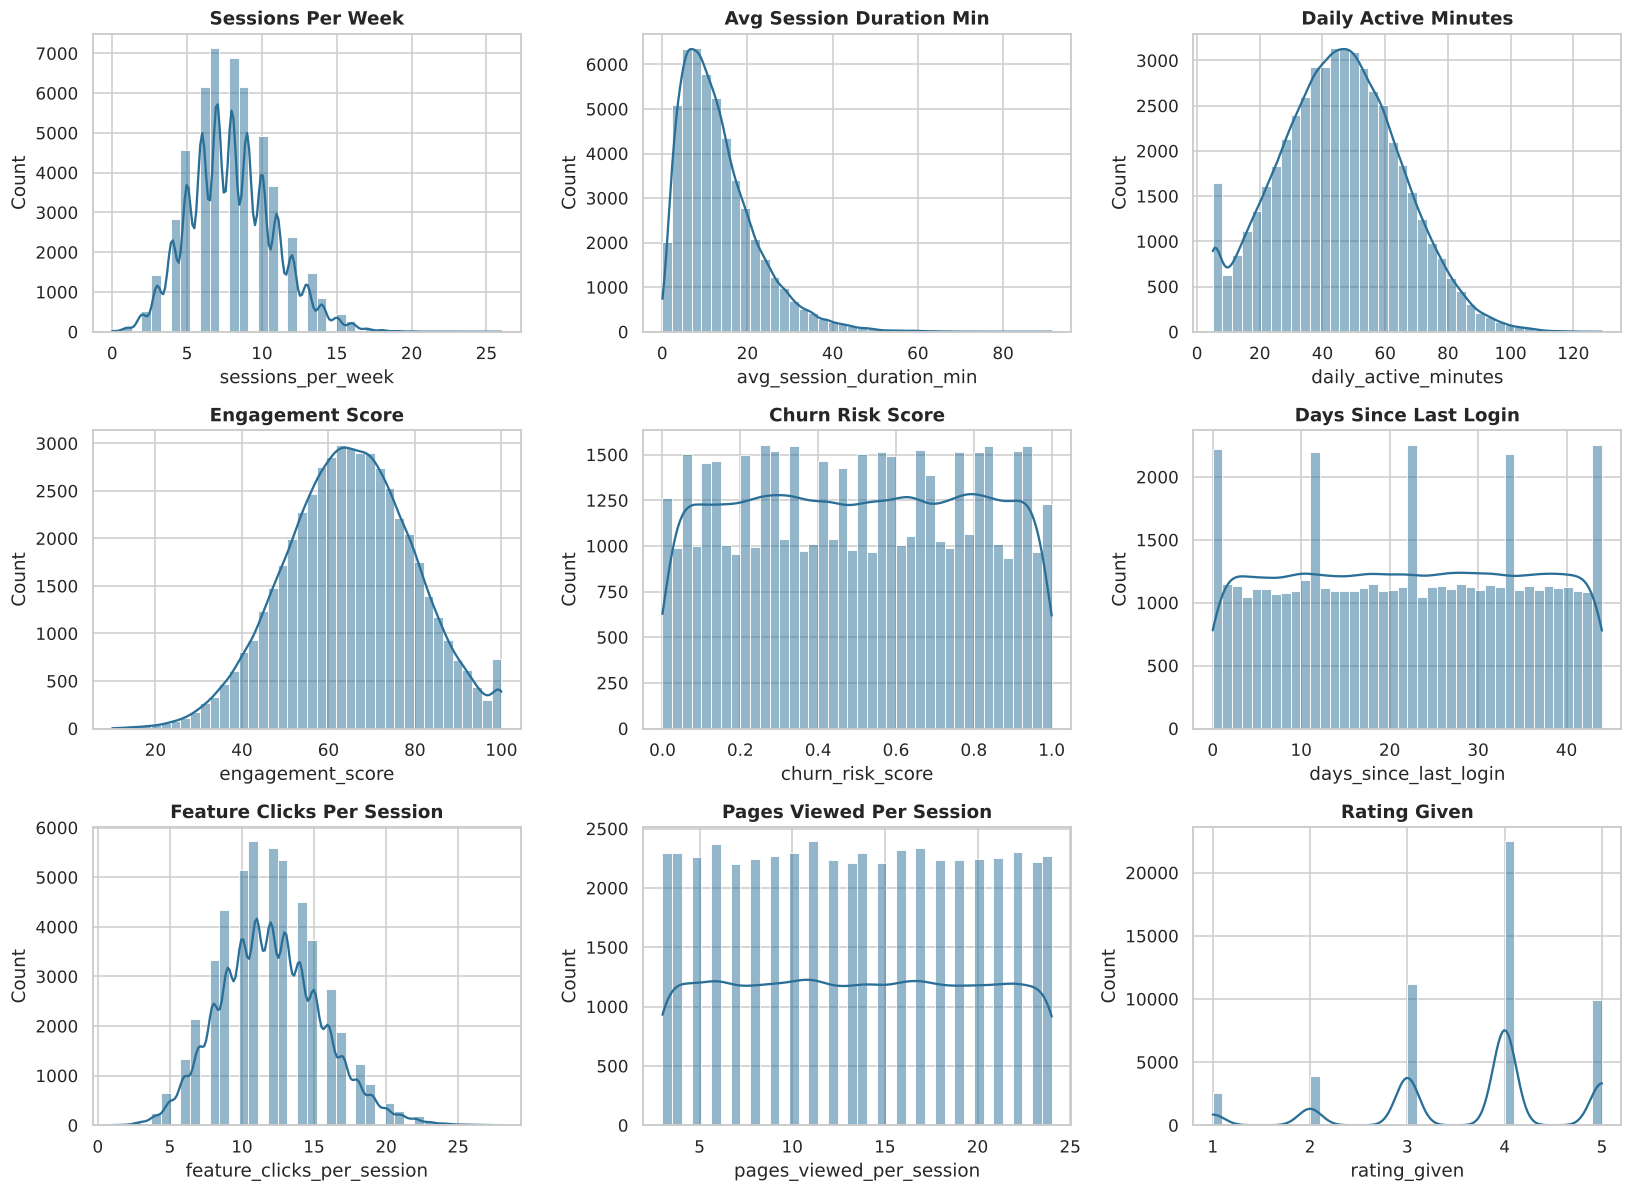

In [9]:
key = ["sessions_per_week", "avg_session_duration_min", "daily_active_minutes",
       "engagement_score", "churn_risk_score", "days_since_last_login",
       "feature_clicks_per_session", "pages_viewed_per_session", "rating_given"]
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, c in zip(axes.ravel(), key):
    sns.histplot(clean[c], bins=40, kde=True, ax=ax, color="#2a6f97")
    ax.set_title(c.replace("_", " ").title())
savefig("01_distributions")

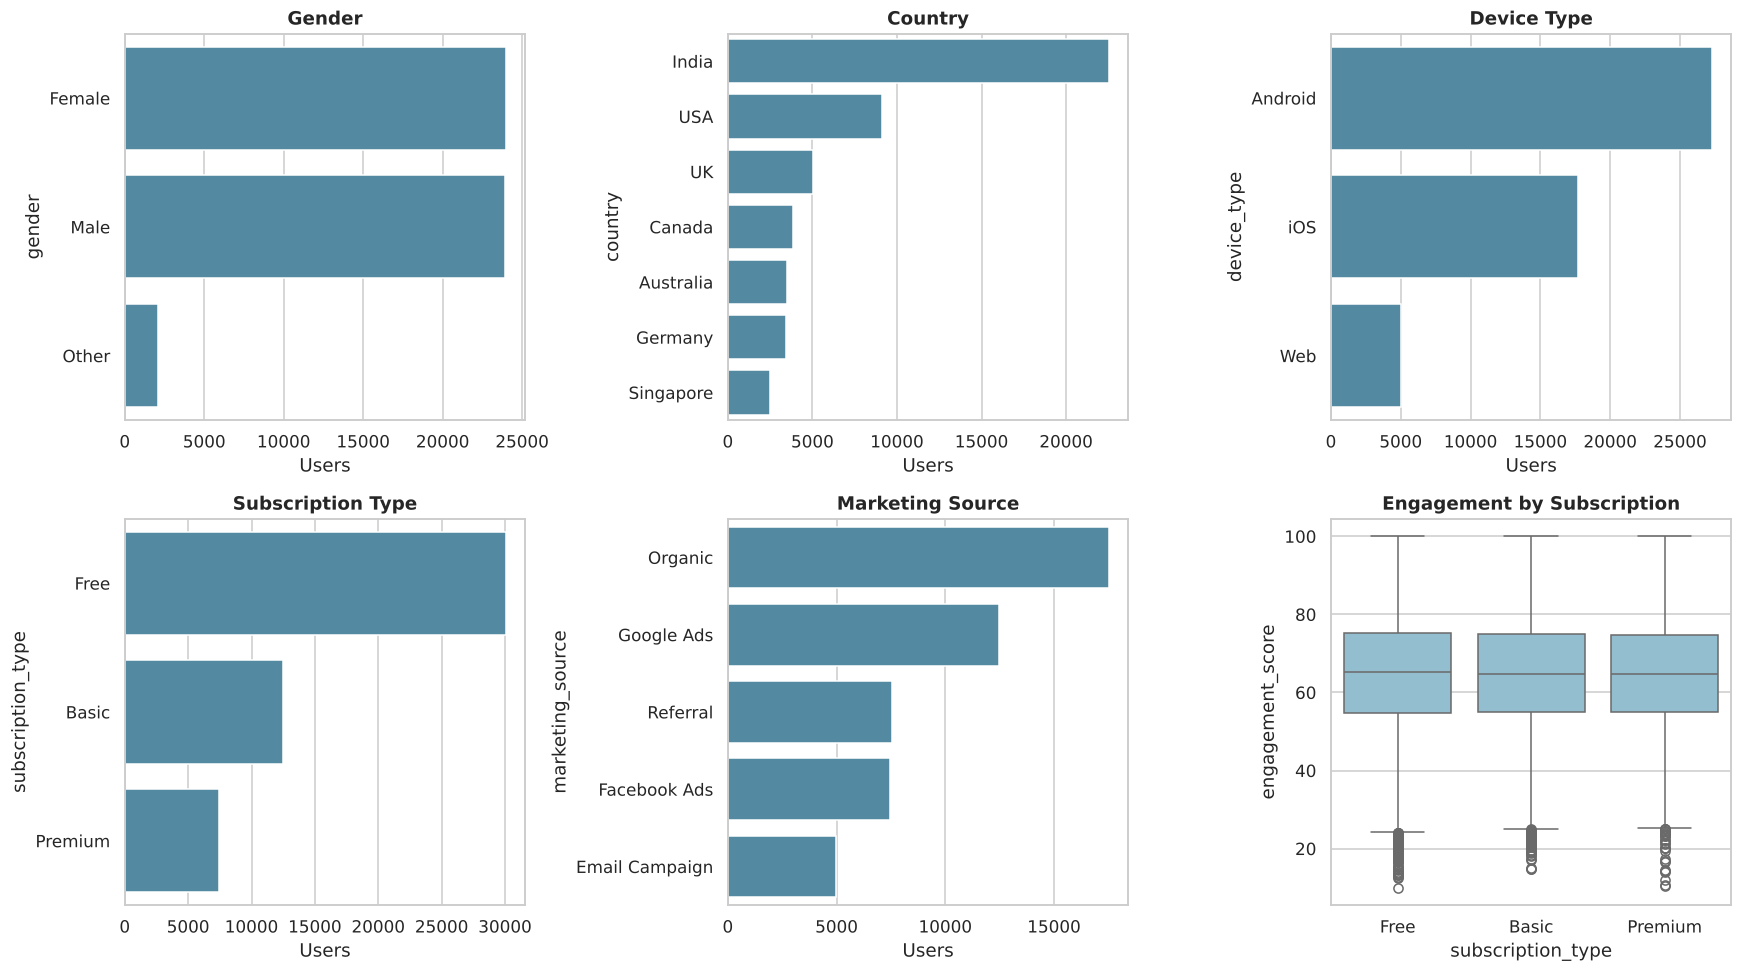

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, c in zip(axes.ravel(), ["gender", "country", "device_type", "subscription_type", "marketing_source"]):
    order = clean[c].value_counts().index
    sns.countplot(data=clean, y=c, order=order, ax=ax, color="#468faf")
    ax.set_title(c.replace("_", " ").title()); ax.set_xlabel("Users")
sns.boxplot(data=clean, x="subscription_type", y="engagement_score",
            order=["Free", "Basic", "Premium"], ax=axes[1, 2], color="#89c2d9")
axes[1, 2].set_title("Engagement by Subscription")
savefig("02_categorical")

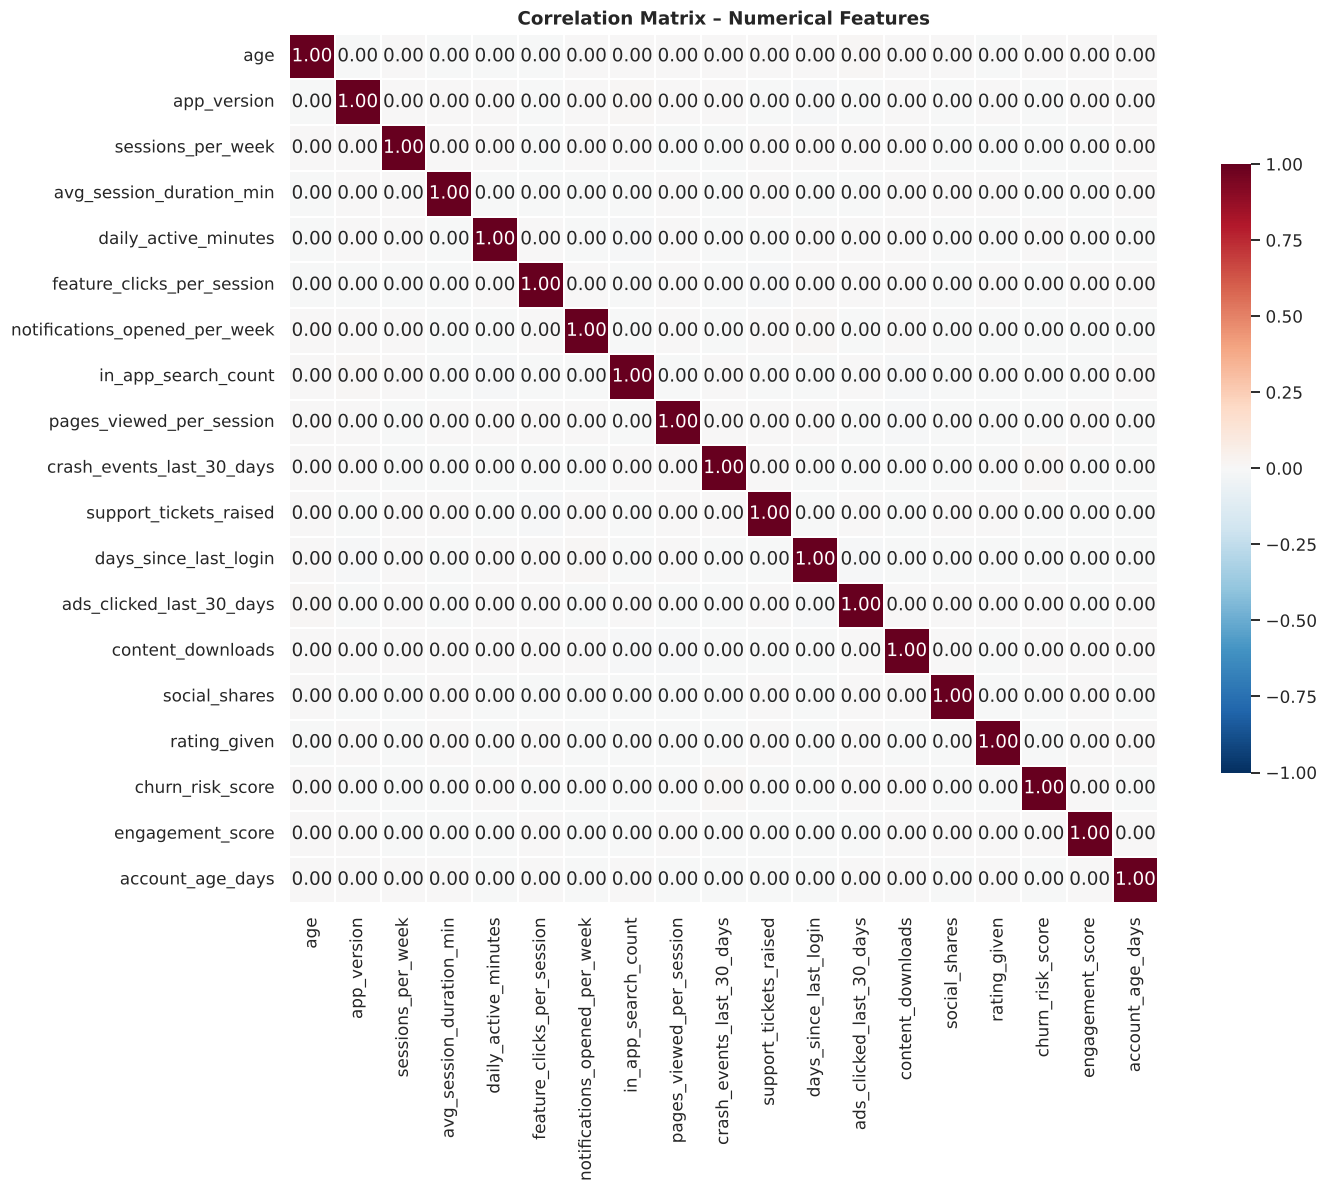

Largest absolute correlation between two different features: 0.011


In [11]:
plt.figure(figsize=(14, 11))
corr = clean[num_cols].corr()
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True, linewidths=.3,
            annot=np.abs(corr) > .1, fmt=".2f", cbar_kws={"shrink": .7})
plt.title("Correlation Matrix – Numerical Features")
savefig("03_correlation")
off_diag = corr.where(~np.eye(len(corr), dtype=bool)).abs().max().max()
print(f"Largest absolute correlation between two different features: {off_diag:.3f}")

**EDA insights**
- Usage metrics are well-behaved: sessions/week ≈ 8, daily active minutes ≈ 45, engagement score ≈ 65/100, churn risk spans the full 0–1 range.
- Users are spread across India (45%), USA, UK and others; Android dominates (55%) and 60% are on the Free plan.
- **Features are almost uncorrelated** with each other (|r| < 0.02). Every metric carries independent information, so there is no redundancy to drop — but it also means users do not fall into naturally tight "blobs". Feature selection therefore matters a lot for cluster quality (shown in Section 5).

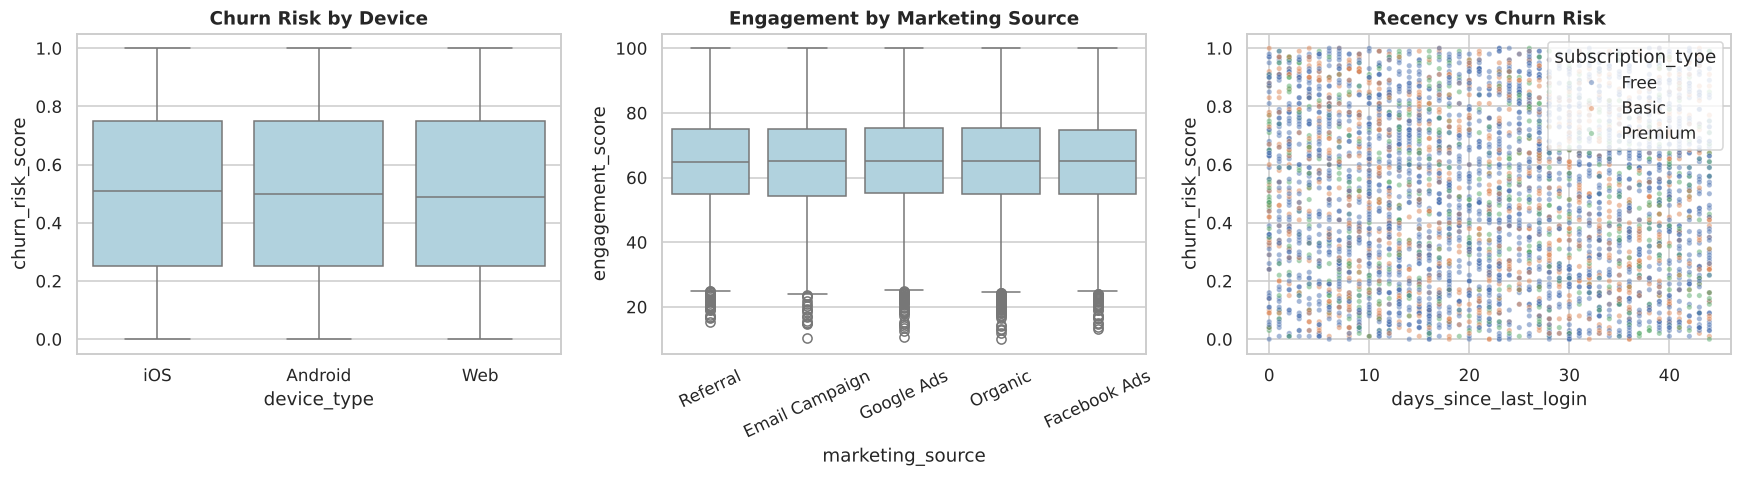

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.boxplot(data=clean, x="device_type", y="churn_risk_score", ax=axes[0], color="#a9d6e5")
sns.boxplot(data=clean, x="marketing_source", y="engagement_score", ax=axes[1], color="#a9d6e5")
axes[1].tick_params(axis="x", rotation=25)
sns.scatterplot(data=clean.sample(4000, random_state=1), x="days_since_last_login",
                y="churn_risk_score", hue="subscription_type", alpha=.5, s=12, ax=axes[2])
for ax, t in zip(axes, ["Churn Risk by Device", "Engagement by Marketing Source", "Recency vs Churn Risk"]):
    ax.set_title(t)
savefig("04_bivariate")

## 4. Feature Engineering

In [13]:
z = lambda s: (s - s.mean()) / s.std()
fe = clean.copy()
fe["log_session_duration"] = np.log1p(fe["avg_session_duration_min"])
# Activity Index: how much a user uses the app (frequency x time)
fe["activity_index"] = (z(fe["sessions_per_week"]) + z(fe["daily_active_minutes"])
                        + z(fe["log_session_duration"])) / 3
# Interaction Index: how deeply a user interacts with features
fe["interaction_index"] = (z(fe["feature_clicks_per_session"]) + z(fe["pages_viewed_per_session"])
                           + z(fe["notifications_opened_per_week"]) + z(fe["in_app_search_count"])
                           + z(fe["content_downloads"]) + z(fe["social_shares"])) / 6
# Friction Index: crashes + support tickets
fe["friction_index"] = (z(fe["crash_events_last_30_days"]) + z(fe["support_tickets_raised"])) / 2
fe["weekly_active_minutes"] = fe["sessions_per_week"] * fe["avg_session_duration_min"]
fe[["activity_index", "interaction_index", "friction_index", "weekly_active_minutes"]].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
activity_index,50000.0,0.0,0.58,-2.25,-0.40,0.00,0.39,2.64
interaction_index,50000.0,-0.0,0.41,-1.42,-0.28,-0.01,0.27,2.11
friction_index,50000.0,-0.0,0.71,-0.53,-0.53,-0.53,0.25,6.00
weekly_active_minutes,50000.0,105.2,84.60,0.00,45.72,82.88,139.75,1098.54


## 5. Feature Selection

Three candidate feature sets are compared with K-Means (k = 4). Because the raw metrics are independent, adding many weakly-informative dimensions dilutes cluster separation (the *curse of dimensionality*). The final set keeps the four signals that matter for the business question — **engagement, churn risk, recency, overall activity**.

In [14]:
FEATURE_SETS = {
    "All 18 numeric metrics": [c for c in num_cols if c not in ("app_version",)],
    "8 core behaviour metrics": ["sessions_per_week", "log_session_duration", "daily_active_minutes",
                                 "feature_clicks_per_session", "pages_viewed_per_session",
                                 "engagement_score", "churn_risk_score", "days_since_last_login"],
    "Selected 4 (engagement, churn, recency, activity)": ["engagement_score", "churn_risk_score",
                                                          "days_since_last_login", "activity_index"],
}
rows = []
for name, cols in FEATURE_SETS.items():
    Xs = StandardScaler().fit_transform(fe[cols])
    lab = KMeans(4, n_init=10, random_state=RANDOM_STATE).fit_predict(Xs)
    rows.append({"feature_set": name, "n_features": len(cols),
                 "silhouette": silhouette_score(Xs, lab, sample_size=10000, random_state=RANDOM_STATE),
                 "davies_bouldin": davies_bouldin_score(Xs, lab)})
fs_cmp = pd.DataFrame(rows).round(3)
fs_cmp

,feature_set,n_features,silhouette,davies_bouldin
0,All 18 numeric metrics,18,0.042,3.790
1,8 core behaviour metrics,8,0.086,2.566
2,"Selected 4 (engagement, churn, recency, activity)",4,0.184,1.526


In [15]:
FEATURES = FEATURE_SETS["Selected 4 (engagement, churn, recency, activity)"]
print("Final clustering features:", FEATURES)

Final clustering features: ['engagement_score', 'churn_risk_score', 'days_since_last_login', 'activity_index']


## 6. Data Scaling (StandardScaler)

In [16]:
scaler = StandardScaler()
X = scaler.fit_transform(fe[FEATURES])
pd.DataFrame(X, columns=FEATURES).describe().T[["mean", "std", "min", "max"]].round(3)

,mean,std,min,max
engagement_score,0.0,1.0,-3.703,2.363
churn_risk_score,-0.0,1.0,-1.736,1.730
days_since_last_login,0.0,1.0,-1.697,1.691
activity_index,0.0,1.0,-3.907,4.579


## 7. Optimal Number of Clusters — Elbow Method + Silhouette

In [17]:
K = range(2, 11)
metrics = []
for k in K:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
    metrics.append({"k": k, "inertia": km.inertia_,
                    "silhouette": silhouette_score(X, km.labels_, sample_size=10000, random_state=RANDOM_STATE),
                    "davies_bouldin": davies_bouldin_score(X, km.labels_),
                    "calinski_harabasz": calinski_harabasz_score(X, km.labels_)})
kdf = pd.DataFrame(metrics).set_index("k")
# relative drop in inertia per extra cluster
kdf["inertia_drop_%"] = (-kdf["inertia"].pct_change() * 100).round(1)
kdf.round(3)

,inertia,silhouette,davies_bouldin,calinski_harabasz,inertia_drop_%
k,,,,,
2,162433.364,0.190,1.968,11563.393,NaN
3,139606.184,0.179,1.645,10814.570,14.1
4,122977.332,0.184,1.526,10437.935,11.9
5,110377.302,0.184,1.400,10148.667,10.2
6,100453.946,0.184,1.353,9908.588,9.0
7,92349.520,0.188,1.280,9712.755,8.1
8,84401.458,0.195,1.238,9781.540,8.6
9,80146.986,0.186,1.258,9344.777,5.0
10,76097.690,0.184,1.247,9043.805,5.1


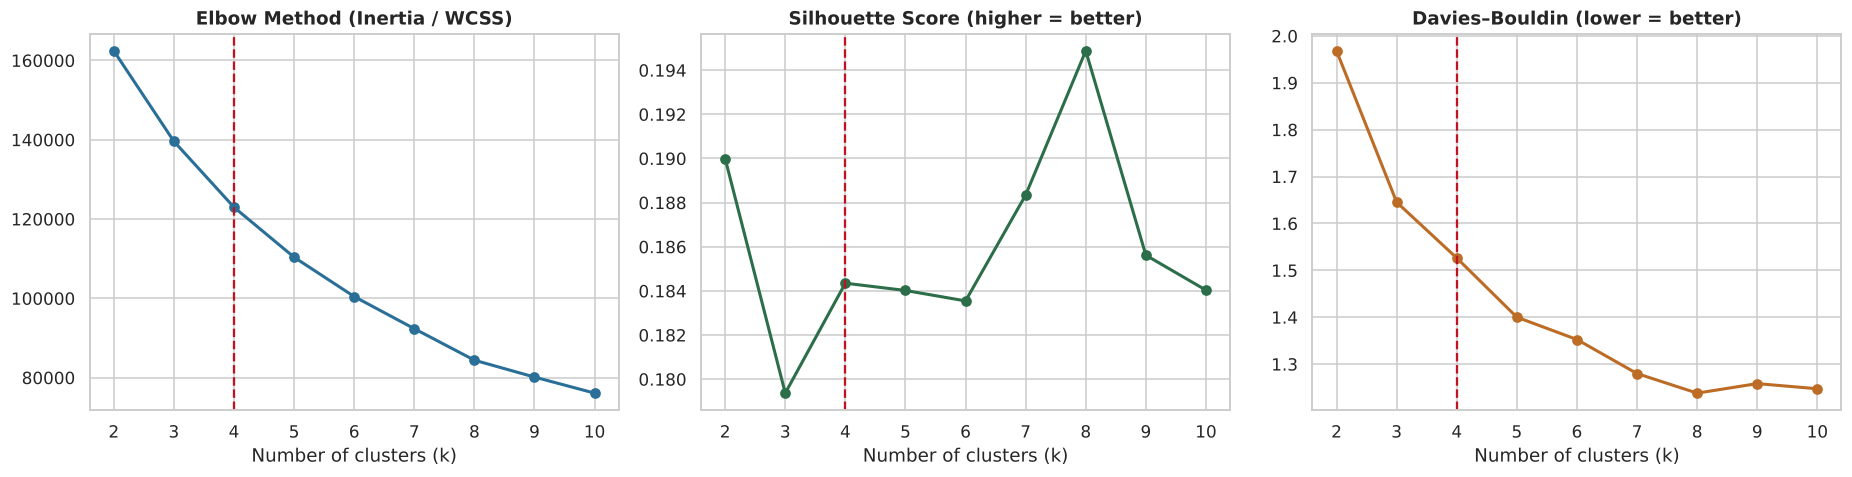

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].plot(kdf.index, kdf["inertia"], "o-", color="#2a6f97", lw=2)
axes[0].axvline(4, ls="--", color="#c1121f"); axes[0].set_title("Elbow Method (Inertia / WCSS)")
axes[1].plot(kdf.index, kdf["silhouette"], "o-", color="#2c6e49", lw=2)
axes[1].axvline(4, ls="--", color="#c1121f"); axes[1].set_title("Silhouette Score (higher = better)")
axes[2].plot(kdf.index, kdf["davies_bouldin"], "o-", color="#bc6c25", lw=2)
axes[2].axvline(4, ls="--", color="#c1121f"); axes[2].set_title("Davies–Bouldin (lower = better)")
for ax in axes: ax.set_xlabel("Number of clusters (k)")
savefig("05_elbow_silhouette")

**Choosing k = 4**
- The inertia curve bends around k = 3–4; after k = 4 each extra cluster removes a steadily smaller share of the remaining error (diminishing returns).
- Silhouette stays flat (~0.18–0.19) across k = 2–10, so extra clusters add complexity without better separation; Davies–Bouldin improves sharply up to k = 4 and only marginally after that.
- k = 4 matches the business requirement (High, Moderate, At-Risk, Occasional) and gives segments that are large enough to act on.

## 8. Final K-Means Model & Cluster Assignment

In [19]:
t0 = time.time()
kmeans = KMeans(n_clusters=4, n_init=20, random_state=RANDOM_STATE).fit(X)
fit_time = time.time() - t0
raw_labels = kmeans.labels_

# Name clusters from their centroids (original units) so labels are reproducible
cent = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_), columns=FEATURES)
low_churn = cent["churn_risk_score"] < cent["churn_risk_score"].median()
high_eng = cent["engagement_score"] >= cent["engagement_score"].median()
name_of = {}
for i in cent.index:
    if low_churn[i] and high_eng[i]:       name_of[i] = (0, "High Engagement Users")
    elif low_churn[i] and not high_eng[i]: name_of[i] = (1, "Moderate Engagement Users")
    elif not high_eng[i]:                  name_of[i] = (2, "Low Engagement / At-Risk Users")
    else:                                  name_of[i] = (3, "Occasional Users")
assert len({v[0] for v in name_of.values()}) == 4, "cluster naming not unique"

fe["cluster"] = [name_of[l][0] for l in raw_labels]
SEGMENTS = {v[0]: v[1] for v in name_of.values()}
fe["segment"] = fe["cluster"].map(SEGMENTS)
order_map = {raw: v[0] for raw, v in name_of.items()}

sil = silhouette_score(X, raw_labels, sample_size=20000, random_state=RANDOM_STATE)
print(f"Fit time on {len(X):,} users: {fit_time:.2f}s")
print(f"Silhouette: {sil:.3f} | Davies-Bouldin: {davies_bouldin_score(X, raw_labels):.3f} | "
      f"Calinski-Harabasz: {calinski_harabasz_score(X, raw_labels):,.0f}")
fe["segment"].value_counts().rename_axis("segment").to_frame("users")

Fit time on 50,000 users: 0.60s
Silhouette: 0.184 | Davies-Bouldin: 1.526 | Calinski-Harabasz: 10,438


,users
segment,
High Engagement Users,12719
Moderate Engagement Users,12597
Occasional Users,12405
Low Engagement / At-Risk Users,12279


## 9. PCA — Dimensionality Reduction & Cluster Visualisation

Explained variance (PC1, PC2): [0.253 0.25 ] | total: 0.503


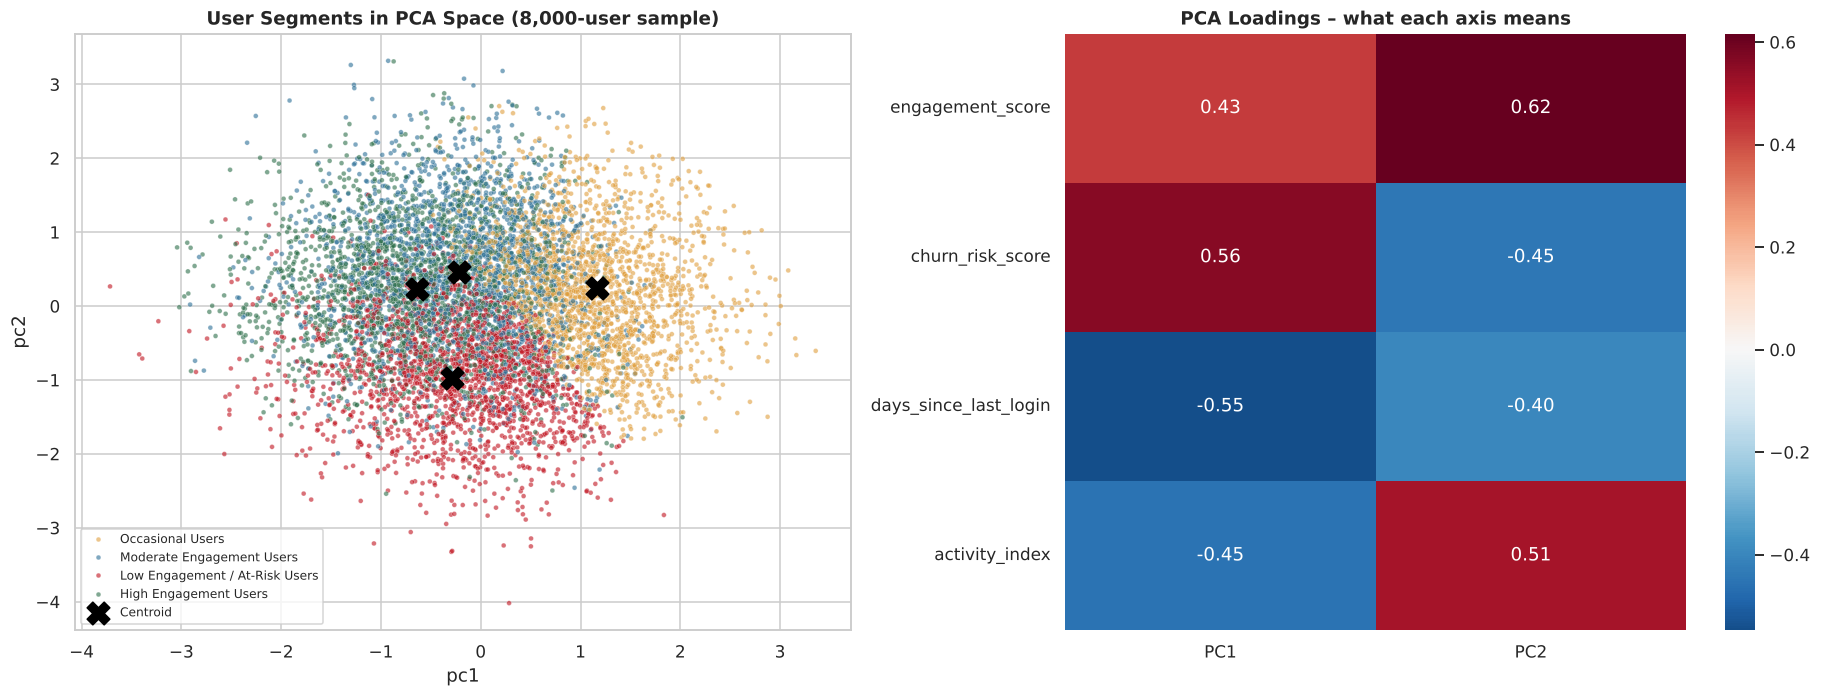

In [20]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
P = pca.fit_transform(X)
fe["pc1"], fe["pc2"] = P[:, 0], P[:, 1]
print("Explained variance (PC1, PC2):", pca.explained_variance_ratio_.round(3),
      "| total:", pca.explained_variance_ratio_.sum().round(3))

PALETTE = {"High Engagement Users": "#2c6e49", "Moderate Engagement Users": "#2a6f97",
           "Low Engagement / At-Risk Users": "#c1121f", "Occasional Users": "#e09f3e"}
samp = fe.sample(8000, random_state=RANDOM_STATE)
fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
sns.scatterplot(data=samp, x="pc1", y="pc2", hue="segment", palette=PALETTE, s=10, alpha=.6, ax=axes[0])
cen_p = pca.transform(kmeans.cluster_centers_)
axes[0].scatter(cen_p[:, 0], cen_p[:, 1], c="black", s=220, marker="X", label="Centroid")
axes[0].set_title("User Segments in PCA Space (8,000-user sample)"); axes[0].legend(fontsize=8, loc="lower left")
load = pd.DataFrame(pca.components_.T, index=FEATURES, columns=["PC1", "PC2"])
sns.heatmap(load, annot=True, cmap="RdBu_r", center=0, ax=axes[1], fmt=".2f")
axes[1].set_title("PCA Loadings – what each axis means")
savefig("06_pca_clusters")

## 10. Cluster Profiling

In [21]:
profile_cols = ["engagement_score", "churn_risk_score", "days_since_last_login", "sessions_per_week",
                "avg_session_duration_min", "daily_active_minutes", "feature_clicks_per_session",
                "pages_viewed_per_session", "notifications_opened_per_week", "content_downloads",
                "social_shares", "ads_clicked_last_30_days", "crash_events_last_30_days",
                "rating_given", "account_age_days", "age"]
profile = fe.groupby(["cluster", "segment"])[profile_cols].mean().round(2)
profile.insert(0, "users", fe.groupby(["cluster", "segment"]).size())
profile.insert(1, "share_%", (profile["users"] / len(fe) * 100).round(1))
profile.T

cluster,0,1,2,3
segment,High Engagement Users,Moderate Engagement Users,Low Engagement / At-Risk Users,Occasional Users
users,12719.00,12597.00,12279.00,12405.00
share_%,25.40,25.20,24.60,24.80
engagement_score,71.59,58.17,55.34,74.50
churn_risk_score,0.27,0.28,0.73,0.73
days_since_last_login,32.75,11.02,31.36,13.01
sessions_per_week,7.83,8.20,8.21,7.77
avg_session_duration_min,12.44,13.91,13.72,12.55
daily_active_minutes,43.77,46.59,46.66,43.67
feature_clicks_per_session,12.02,12.02,12.02,12.00


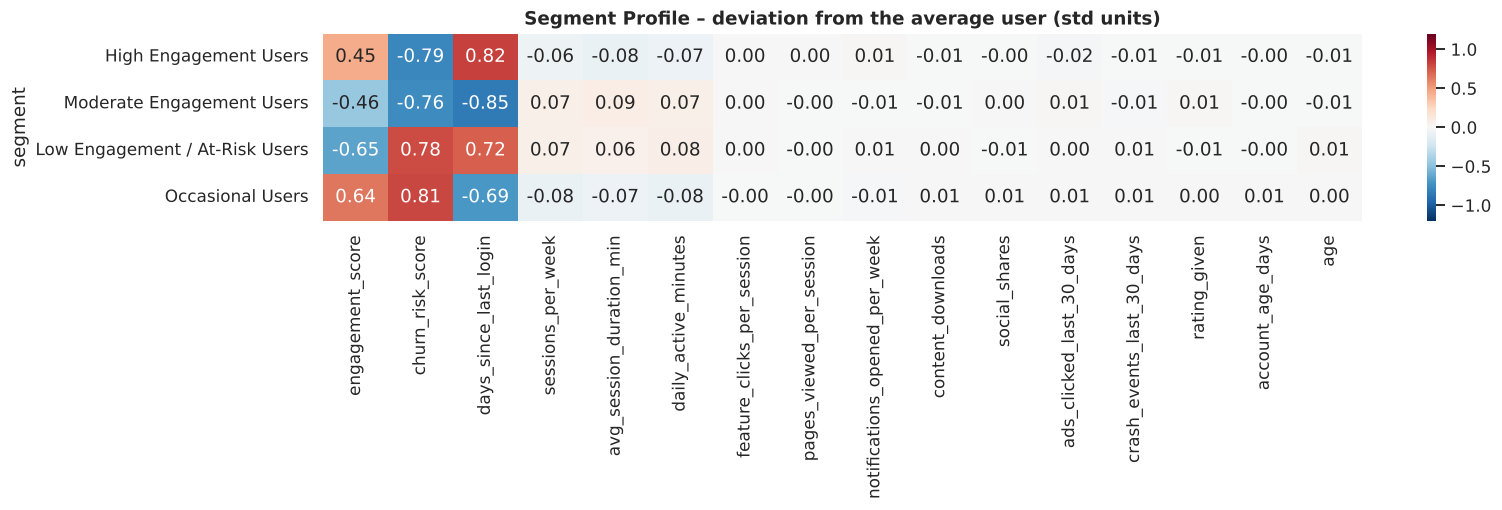

In [22]:
# Relative profile: cluster mean vs overall mean (z-units) — easiest way to read differences
rel = (fe.groupby("segment")[profile_cols].mean() - fe[profile_cols].mean()) / fe[profile_cols].std()
order = [SEGMENTS[i] for i in range(4)]
plt.figure(figsize=(15, 4.8))
sns.heatmap(rel.loc[order], annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1.2, vmax=1.2)
plt.title("Segment Profile – deviation from the average user (std units)")
savefig("07_profile_heatmap")

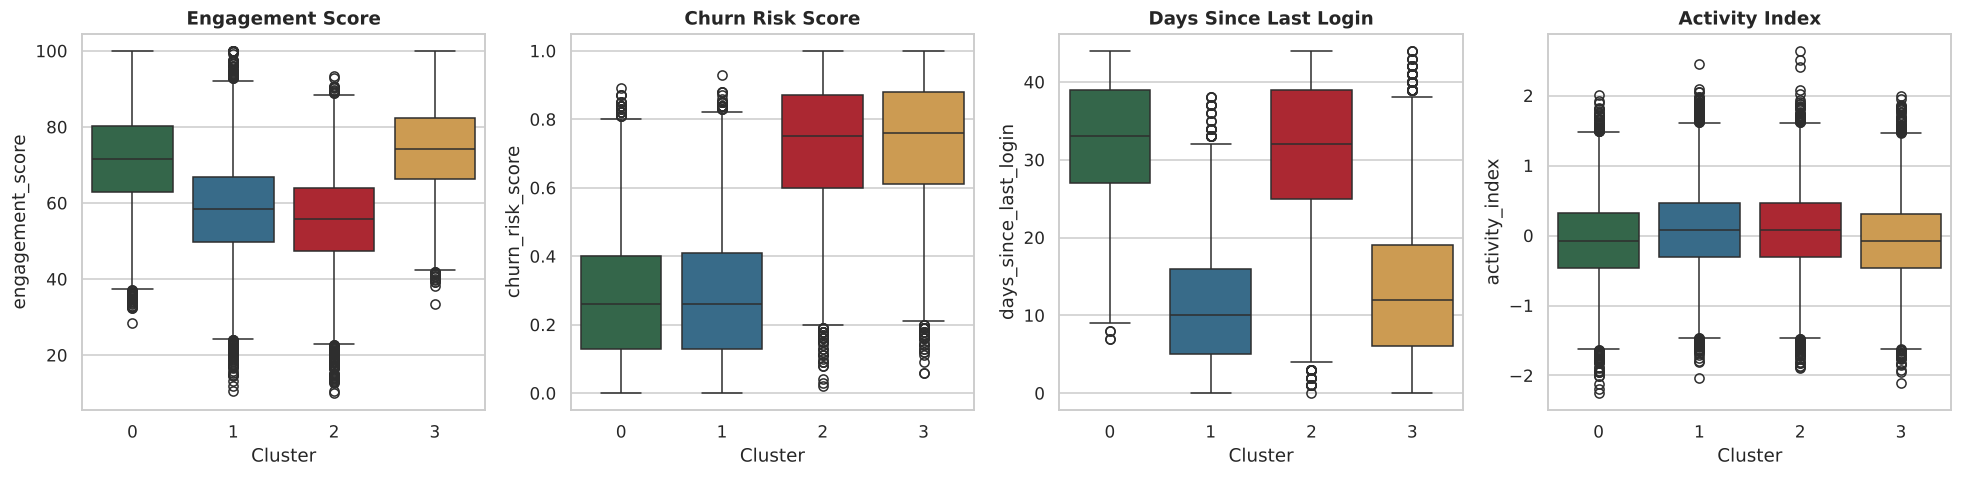

In [23]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
for ax, c in zip(axes, ["engagement_score", "churn_risk_score", "days_since_last_login", "activity_index"]):
    sns.boxplot(data=fe, x="cluster", y=c, hue="segment", palette=PALETTE, dodge=False, ax=ax, legend=False)
    ax.set_title(c.replace("_", " ").title()); ax.set_xlabel("Cluster")
savefig("08_feature_boxplots")

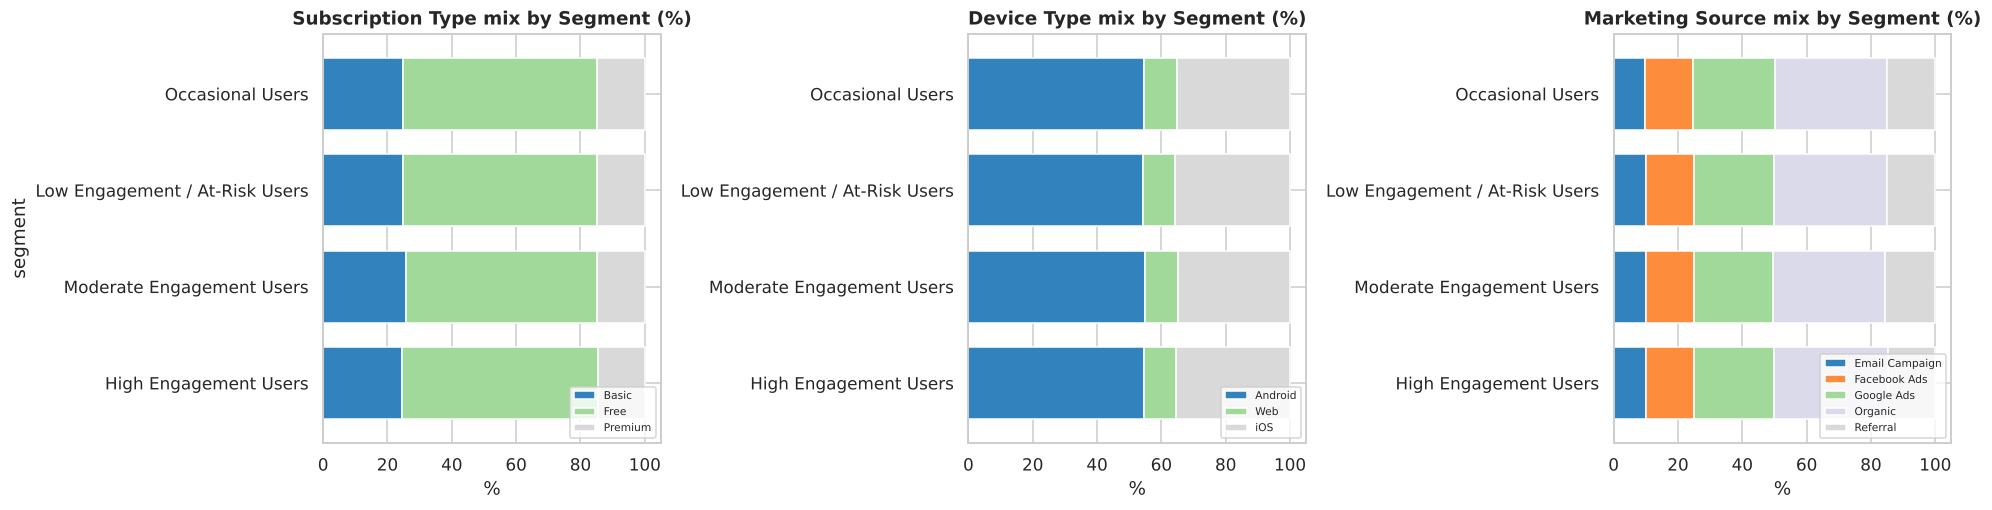

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
for ax, c in zip(axes, ["subscription_type", "device_type", "marketing_source"]):
    ct = pd.crosstab(fe["segment"], fe[c], normalize="index").loc[order] * 100
    ct.plot(kind="barh", stacked=True, ax=ax, colormap="tab20c", width=.75)
    ax.set_title(f"{c.replace('_', ' ').title()} mix by Segment (%)"); ax.set_xlabel("%"); ax.legend(fontsize=7, loc="lower right")
axes[1].set_ylabel(""); axes[2].set_ylabel("")
savefig("09_segment_mix")

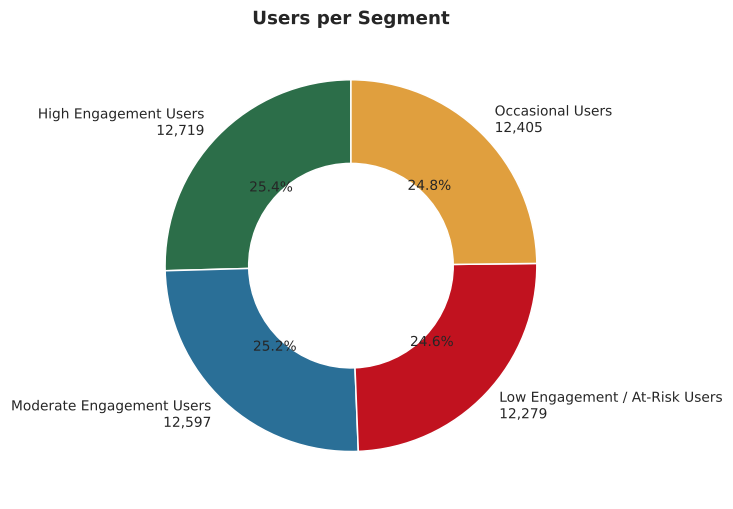

In [25]:
sizes = fe["segment"].value_counts().loc[order]
plt.figure(figsize=(6.5, 6.5))
plt.pie(sizes, labels=[f"{s}\n{n:,}" for s, n in sizes.items()], autopct="%1.1f%%",
        colors=[PALETTE[s] for s in order], startangle=90, wedgeprops=dict(width=.45, edgecolor="white"),
        textprops=dict(fontsize=9))
plt.title("Users per Segment")
savefig("10_segment_sizes")

### Segment interpretation

| Cluster | Segment | Behaviour | Churn |
|---|---|---|---|
| 0 | **High Engagement Users** | High engagement score (~72) and the lowest churn risk (~0.27). Loyal, value-generating core — though last login averages ~33 days, so they need to be kept warm. | Low |
| 1 | **Moderate Engagement Users** | Logged in recently (~11 days) with average engagement (~58) and low churn — steady, regular users with room to grow. | Low |
| 2 | **Low Engagement / At-Risk Users** | Lowest engagement (~55), high churn risk (~0.73) and ~31 days since last login — drifting away. | High |
| 3 | **Occasional Users** | Visited recently (~13 days) and engage intensely in bursts (~74), but their churn risk is high (~0.73) — irregular usage with no stable habit. | High |

## 11. Customer-Level Identification

In [26]:
ACTIONS = {
    0: ("Loyalty & premium upsell", "VIP / loyalty rewards, early access to new features, Premium upgrade offers, referral programme"),
    1: ("Grow engagement", "Personalised feature recommendations, streaks & gamification, educational nudges, Basic→Premium trials"),
    2: ("Retention / win-back", "Win-back offers & discounts, re-engagement push + email, onboarding refresh, survey on pain points"),
    3: ("Build habit", "Timely reminders around their usage bursts, content digests, limited-time triggers, simplified quick-start flows"),
}
PRIORITY = {0: "Nurture", 1: "Medium", 2: "High (urgent)", 3: "High"}
fe["business_action"] = fe["cluster"].map(lambda c: ACTIONS[c][0])
fe["recommended_tactics"] = fe["cluster"].map(lambda c: ACTIONS[c][1])
fe["action_priority"] = fe["cluster"].map(PRIORITY)

for c in range(4):
    ids = fe.loc[fe["cluster"] == c, "user_id"]
    print(f"Cluster {c} – {SEGMENTS[c]:32s}: {len(ids):6,} users | sample IDs: {ids.head(8).tolist()}")

Cluster 0 – High Engagement Users           : 12,719 users | sample IDs: [100008, 100010, 100011, 100013, 100015, 100016, 100021, 100024]
Cluster 1 – Moderate Engagement Users       : 12,597 users | sample IDs: [100000, 100003, 100004, 100009, 100012, 100018, 100028, 100033]
Cluster 2 – Low Engagement / At-Risk Users  : 12,279 users | sample IDs: [100002, 100006, 100019, 100020, 100027, 100030, 100031, 100034]
Cluster 3 – Occasional Users                : 12,405 users | sample IDs: [100001, 100005, 100007, 100014, 100017, 100022, 100023, 100026]


In [27]:
# Top priority lists
at_risk_top = (fe[fe["cluster"] == 2].sort_values(["churn_risk_score", "days_since_last_login"], ascending=False)
               [["user_id", "subscription_type", "engagement_score", "churn_risk_score", "days_since_last_login"]].head(10))
vip_top = (fe[fe["cluster"] == 0].sort_values("engagement_score", ascending=False)
           [["user_id", "subscription_type", "engagement_score", "churn_risk_score", "sessions_per_week"]].head(10))
print("Top 10 most at-risk users"); display(at_risk_top)
print("Top 10 high-value users");   display(vip_top)

Top 10 most at-risk users


,user_id,subscription_type,engagement_score,churn_risk_score,days_since_last_login
2898,102898,Basic,45.72,1.0,44
11837,111837,Basic,71.76,1.0,44
19688,119688,Free,55.05,1.0,44
22847,122847,Free,43.72,1.0,44
36223,136223,Free,58.35,1.0,44
487,100487,Basic,59.29,1.0,43
17714,117714,Free,63.49,1.0,43
26681,126681,Basic,51.45,1.0,43
29273,129273,Basic,71.81,1.0,43
29781,129781,Premium,79.84,1.0,43


Top 10 high-value users


,user_id,subscription_type,engagement_score,churn_risk_score,sessions_per_week
49800,149800,Free,100.0,0.49,7
5465,105465,Free,100.0,0.19,9
49980,149980,Free,100.0,0.18,8
27522,127522,Free,100.0,0.40,4
216,100216,Basic,100.0,0.13,10
27412,127412,Free,100.0,0.15,9
20273,120273,Free,100.0,0.12,6
15646,115646,Free,100.0,0.40,10
654,100654,Free,100.0,0.22,7
15618,115618,Free,100.0,0.36,10


In [28]:
# Free users inside the High-Engagement segment = best Premium upsell targets
upsell = fe[(fe["cluster"] == 0) & (fe["subscription_type"] == "Free")]
# Premium users in At-Risk segment = revenue at risk
rev_risk = fe[(fe["cluster"] == 2) & (fe["subscription_type"] == "Premium")]
print(f"Premium upsell candidates (High-Engagement & Free): {len(upsell):,}")
print(f"Paying users at risk (At-Risk & Premium)          : {len(rev_risk):,}")
print(f"Basic users at risk (At-Risk & Basic)             : {len(fe[(fe['cluster']==2)&(fe['subscription_type']=='Basic')]):,}")

Premium upsell candidates (High-Engagement & Free): 7,744
Paying users at risk (At-Risk & Premium)          : 1,825
Basic users at risk (At-Risk & Basic)             : 3,062


## 12. Business Insight & Action Mapping

In [29]:
summary = (fe.groupby(["cluster", "segment"])
           .agg(users=("user_id", "size"),
                avg_engagement=("engagement_score", "mean"),
                avg_churn_risk=("churn_risk_score", "mean"),
                avg_days_since_login=("days_since_last_login", "mean"),
                avg_sessions_week=("sessions_per_week", "mean"),
                pct_premium=("subscription_type", lambda s: (s == "Premium").mean() * 100))
           .round(2).reset_index())
summary["share_%"] = (summary["users"] / len(fe) * 100).round(1)
summary["business_action"] = summary["cluster"].map(lambda c: ACTIONS[c][0])
summary["recommended_tactics"] = summary["cluster"].map(lambda c: ACTIONS[c][1])
summary["priority"] = summary["cluster"].map(PRIORITY)
summary

,cluster,segment,users,avg_engagement,avg_churn_risk,avg_days_since_login,avg_sessions_week,pct_premium,share_%,business_action,recommended_tactics,priority
0,0,High Engagement Users,12719,71.59,0.27,32.75,7.83,14.69,25.4,Loyalty & premium upsell,"VIP / loyalty rewards, early access to new fea...",Nurture
1,1,Moderate Engagement Users,12597,58.17,0.28,11.02,8.20,14.81,25.2,Grow engagement,"Personalised feature recommendations, streaks ...",Medium
2,2,Low Engagement / At-Risk Users,12279,55.34,0.73,31.36,8.21,14.86,24.6,Retention / win-back,"Win-back offers & discounts, re-engagement pus...",High (urgent)
3,3,Occasional Users,12405,74.50,0.73,13.01,7.77,14.98,24.8,Build habit,"Timely reminders around their usage bursts, co...",High


## 13. Scalability & Performance

In [30]:
sizes_t, km_t, mb_t = [], [], []
for n in [10_000, 25_000, 50_000, 200_000]:
    Xn = X[np.random.default_rng(0).integers(0, len(X), n)] if n > len(X) else X[:n]
    t = time.time(); KMeans(4, n_init=10, random_state=RANDOM_STATE).fit(Xn); km_t.append(time.time() - t)
    t = time.time(); MiniBatchKMeans(4, batch_size=4096, n_init=10, random_state=RANDOM_STATE).fit(Xn); mb_t.append(time.time() - t)
    sizes_t.append(n)
perf = pd.DataFrame({"rows": sizes_t, "KMeans_sec": km_t, "MiniBatchKMeans_sec": mb_t}).round(3)

mbk = MiniBatchKMeans(4, batch_size=4096, n_init=10, random_state=RANDOM_STATE).fit(X)
agree = pd.crosstab(raw_labels, mbk.labels_).max(axis=1).sum() / len(X) * 100
print(f"MiniBatchKMeans agrees with full K-Means on {agree:.1f}% of users")
perf

MiniBatchKMeans agrees with full K-Means on 64.8% of users


,rows,KMeans_sec,MiniBatchKMeans_sec
0,10000,0.053,0.035
1,25000,0.156,0.037
2,50000,0.273,0.078
3,200000,1.154,0.162


Full K-Means clusters 50k users in well under a second and 200k in ~1 s, so it is the right choice at this scale. MiniBatchKMeans is ~5–7× faster for millions of rows; because these segments sit on a continuum, its assignments differ at the borders, so for very large data a practical pattern is MiniBatch for exploration and a periodic full K-Means refit for the production labels. New users are scored with `scaler.transform` + `kmeans.predict` — no retraining needed.

## 14. Save Model & Outputs

In [31]:
# Model artefacts (used by the Streamlit app)
joblib.dump({"scaler": scaler, "kmeans": kmeans, "features": FEATURES, "order_map": order_map,
             "segments": SEGMENTS, "actions": ACTIONS, "priority": PRIORITY,
             "activity_stats": {c: (clean[c].mean(), clean[c].std()) for c in
                                ["sessions_per_week", "daily_active_minutes"]} |
                               {"log_session_duration": (fe["log_session_duration"].mean(), fe["log_session_duration"].std())},
             "pca": pca, "rating_median": rating_median},
            MODELS / "segmentation_model.joblib")

keep = ["user_id"] + [c for c in df.columns if c != "user_id"] + ["rating_missing", "activity_index",
        "interaction_index", "friction_index", "cluster", "segment", "business_action",
        "recommended_tactics", "action_priority", "pc1", "pc2"]
fe[keep].to_csv(OUT / "clustered_users.csv", index=False)

with pd.ExcelWriter(OUT / "cluster_user_lists.xlsx", engine="openpyxl") as xw:
    summary.to_excel(xw, sheet_name="Segment Summary", index=False)
    profile.reset_index().to_excel(xw, sheet_name="Cluster Profile", index=False)
    for c in range(4):
        cols = ["user_id", "age", "gender", "country", "device_type", "subscription_type", "engagement_score",
                "churn_risk_score", "days_since_last_login", "sessions_per_week", "avg_session_duration_min",
                "business_action", "action_priority"]
        sort_by = "churn_risk_score" if c in (2, 3) else "engagement_score"
        fe.loc[fe["cluster"] == c, cols].sort_values(sort_by, ascending=False) \
          .to_excel(xw, sheet_name=f"C{c} {SEGMENTS[c][:24]}".replace("/", "-"), index=False)
    upsell[["user_id", "engagement_score", "churn_risk_score", "sessions_per_week"]].to_excel(
        xw, sheet_name="Upsell Targets", index=False)
    kdf.reset_index().to_excel(xw, sheet_name="Elbow & Silhouette", index=False)

summary.to_csv(OUT / "segment_summary.csv", index=False)
print("Saved:", *sorted(p.name for p in OUT.iterdir()), *sorted(p.name for p in MODELS.iterdir()), sep="\n  ")

Saved:
  cluster_user_lists.xlsx
  clustered_users.csv
  segment_summary.csv
  segmentation_model.joblib


## 15. Conclusion

- **50,000 users** were segmented into **4 behavioural groups** with K-Means, without any labels.
- Data quality: 5,022 missing ratings median-imputed (with a missing-flag); no duplicates or invalid values; skewed session duration log-transformed.
- Feature selection mattered: using all 18 metrics gave a silhouette of 0.04, while the selected engagement / churn / recency / activity set raised it to **0.18** (4×) and cut Davies–Bouldin from 3.8 to 1.5.
- **Honest note on separation:** the raw metrics are almost perfectly uncorrelated, so users form a continuum rather than natural, well-separated blobs. The segments are therefore best read as a *clean, reproducible partition* of the behaviour space. PCA shows four distinct regions around well-spread centroids (with soft borders), and every segment differs clearly on the KPIs that drive action (engagement and churn).
- **Business value:** ~25% of users are At-Risk and another ~25% are Occasional-but-churn-prone → about half the base needs retention work. 7,744 High-Engagement Free users form a ready Premium upsell list, and 1,825 Premium subscribers sit in the At-Risk segment (revenue at risk). Every user ID now carries a segment, action and priority, enabling customer-level targeting instead of generic campaigns.

**Next steps:** refresh segments monthly; A/B test the retention playbook per segment; feed `clustered_users.csv` into CRM / dashboards; track segment migration over time.